# Digital Image Processing — Week 5 · Task 5

**Grup: Nmertgules ve Iliya**

X-ray görüntülerini griye çevirip güvenlik operatörleri için yeniden renklendirme

Veri: [HUMS X-ray Dataset](https://www.kaggle.com/datasets/orvile/hums-x-ray-dataset). Görevde klasör adı "ThreadsRGB" olarak geçiyor; veri setindeki gerçek adı **`ThreatsRGB`**'dir (bıçak içeren, sahte renkli 150 görüntü). Veri seti çift enerjili (yüksek/düşük enerji) bir X-ray tarayıcıdan toplanmıştır.

Adımlar:

1. `ThreatsRGB` içinden seçilen 5 görüntü, Task 3'teki kendi fonksiyonumuzla griye çevrilir.
2. Gri görüntü, operatörlerin alışık olduğu renk düzenine göre tasarladığımız bir paletle renklendirilir.
3. Palet seçiminin nedeni açıklanır; üretilen görüntü orijinal renkli görüntüyle sayısal ve görsel olarak karşılaştırılıp farklar yorumlanır.

In [1]:
from pathlib import Path
import subprocess, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore', message='IProgress not found')   # kagglehub ilerleme çubuğu uyarısı
try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
    import kagglehub

# Veri seti herkese açık; kagglehub indirir ve önbelleğe alır (~128 MB).
DATASET = Path(kagglehub.dataset_download('orvile/hums-x-ray-dataset'))
THREATS = next(p for p in DATASET.rglob('ThreatsRGB') if p.is_dir())
all_files = sorted(THREATS.glob('*.jpg'))

HERE = Path('week5') if Path('week5').is_dir() else Path('.')
OUT = HERE / 'results'
OUT.mkdir(parents=True, exist_ok=True)

# Farklı içerikte 5 görüntü: test kiti, bıçaklı çanta, organik şişe + bıçaklar, tarama çizgili
# görüntü ve metal çubuklu çanta.
SELECTED = ['image_0_1072.jpg', 'image_0_1212.jpg', 'image_0_1302.jpg', 'image_0_1480.jpg', 'image_0_1922.jpg']
originals = [cv2.imread(str(THREATS / name), cv2.IMREAD_COLOR) for name in SELECTED]
assert all(im is not None for im in originals)
print(f'ThreatsRGB: {len(all_files)} görüntü · seçilenler:')
for name, im in zip(SELECTED, originals):
    print(f'  {name}: {im.shape[1]} × {im.shape[0]}')

ThreatsRGB: 150 görüntü · seçilenler:
  image_0_1072.jpg: 581 × 478
  image_0_1212.jpg: 793 × 584
  image_0_1302.jpg: 824 × 562
  image_0_1480.jpg: 742 × 491
  image_0_1922.jpg: 744 × 486


## 1. Griye çevirme

Task 3'teki `bgr_to_gray` fonksiyonu (BT.601 ağırlıkları, OpenCV ile birebir aynı sabit noktalı hesap) kullanılır.

In [2]:
def bgr_to_gray(img):
    b, g, r = (img[..., i].astype(np.int32) for i in range(3))
    return ((b * 3735 + g * 19235 + r * 9798 + (1 << 14)) >> 15).astype(np.uint8)

grays = [bgr_to_gray(im) for im in originals]
for name, im, g in zip(SELECTED, originals, grays):
    assert np.array_equal(g, cv2.cvtColor(im, cv2.COLOR_BGR2GRAY))
print('5 görüntü griye çevrildi (OpenCV ile hata değeri 0).')

5 görüntü griye çevrildi (OpenCV ile hata değeri 0).


## 2. Palet neden böyle?

**Operatörlerin bildiği renk dili.** Havalimanı ve gümrük tarayıcıları çift enerjili görüntüleri standart bir düzenle gösterir: **turuncu** organik maddeler (gıda, plastik, patlayıcıların çoğu), **yeşil** karışık maddeler ve hafif metaller, **mavi** inorganik maddeler ve metaller, çok koyu renk ise içinden geçilemeyen yoğun bölgeler. Operatörler bu renklerle eğitilir. Aynı renk dilini kullanırsak renklendirilmiş görüntü yeni bir şey öğrenmeden okunur ve bıçak gibi metal nesneler alıştıkları mavide görünür.

**Gri seviyeye göre hangi renk?** Gri görüntüde yalnızca zayıflama (ne kadar koyu) bilgisi var. Hangi gri seviyenin hangi renge karşılık geldiğini tahmin etmek yerine veri setinin kendisine baktık: aşağıdaki hücre, seçtiğimiz 5 görüntü **dışındaki** 145 ThreatsRGB görüntüsünde her gri seviyede orijinalde hangi rengin ne sıklıkta görüldüğünü sayar. Sonuç:

- koyu ve orta seviyelerde (≈0–145) baskın renk **mavi**,
- ≈145–175 arasında mavi, yeşil ve turuncu neredeyse eşit; bu bölge gri bilgiyle gerçekten **belirsiz**,
- ≈175–220 arasında **turuncu**,
- ≈222–243 arasında soluk sarı-yeşil (çok ince madde), daha açığı arka plan.

Palet bu sırayı izler: maviden turuncuya geçerken belirsiz bölgeye dar bir yeşil bant koyduk. Yeşil, operatör için zaten "karışık / emin değilim" anlamına gelir; belirsiz seviyeler için doğru mesaj budur.

**Parlaklık gri seviyeyi izler.** Paletin her rengi, açıklığı (CIELAB `L*`) gri seviyeden alınarak üretildi; yalnızca ton ve doygunluk (`a*`, `b*`) eklendi. Böylece açıklık tekdüze artar, görüntüdeki ayrıntı kaybolmaz ve gökkuşağı (JET) paletlerindeki gibi yapay kenarlar oluşmaz. Arka plan neredeyse beyaz kalır; göz yorulmaz ve nesneler öne çıkar. En koyu bölgeler lacivert-siyaha gider: "içi görülemiyor, elle kontrol et" anlamına gelir.

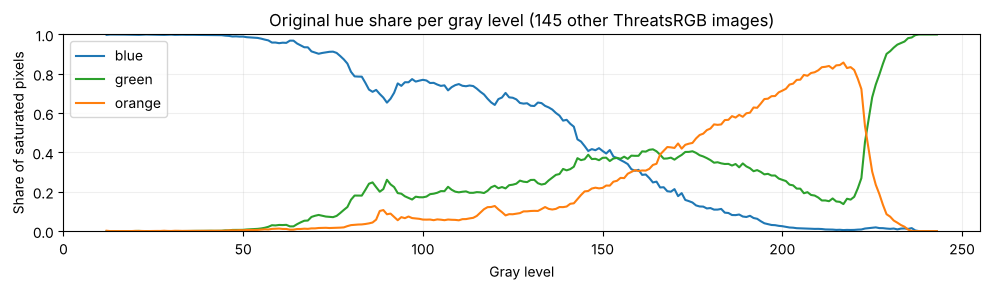

Gri   0–144: mavi 0.79 · yeşil 0.15 · turuncu 0.06
Gri 145–159: mavi 0.38 · yeşil 0.37 · turuncu 0.24
Gri 160–249: mavi 0.07 · yeşil 0.32 · turuncu 0.62
Yeşilin herhangi bir gri seviyedeki en yüksek payı: 1.00 (gri 238)
Doygun renkli piksel bulunan en açık seviye: 243 (daha açığı arka plan)


In [3]:
# Seçilen 5 görüntü dışındaki görüntülerde her gri seviye için orijinal rengin ton dağılımı.
train_files = [f for f in all_files if f.name not in SELECTED]
# Ton aralıkları (derece). 40–75° arası soluk sarı/krem tonlar arka plana ait olduğu için sınıflanmaz;
# 270–310° arası mor tonlar tarama artefaktlarıdır.
TONES = {'blue': (180, 260), 'green': (75, 180), 'orange': (0, 40)}

def tone_class(bgr_img):
    """Doygun pikselleri mavi / yeşil / turuncu olarak etiketle; doygun olmayanlar (arka plan) 'none'."""
    hsv = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2HSV)
    hue, sat = hsv[..., 0].astype(int) * 2, hsv[..., 1]
    labels = np.zeros(hue.shape, np.uint8)
    for k, (lo, hi) in enumerate(TONES.values(), start=1):
        labels[(sat > 60) & (hue >= lo) & (hue < hi)] = k
    labels[(sat > 60) & (hue >= 330)] = 3   # kırmızıya yakın turuncular
    return labels

counts = np.zeros((256, 4))
for f in train_files:
    im = cv2.imread(str(f))
    np.add.at(counts, (bgr_to_gray(im).ravel(), tone_class(im).ravel()), 1)

colored_px = counts[:, 1:].sum(1)
enough = colored_px >= 2000          # yeterli doygun piksel olan seviyeler
share = np.where(enough[:, None], counts[:, 1:] / np.maximum(colored_px[:, None], 1), np.nan)
fig, ax = plt.subplots(figsize=(10, 3))
for k, (name, color) in enumerate(zip(TONES, ['tab:blue', 'tab:green', 'tab:orange'])):
    ax.plot(share[:, k], color=color, label=name)
ax.set(title=f'Original hue share per gray level ({len(train_files)} other ThreatsRGB images)',
       xlabel='Gray level', ylabel='Share of saturated pixels', xlim=(0, 255), ylim=(0, 1))
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout(); plt.show()
for lo, hi in [(0, 145), (145, 160), (160, 250)]:
    sl = counts[lo:hi, 1:].sum(0) / counts[lo:hi, 1:].sum()
    print(f'Gri {lo:3d}–{hi - 1:3d}: mavi {sl[0]:.2f} · yeşil {sl[1]:.2f} · turuncu {sl[2]:.2f}')
print(f'Yeşilin herhangi bir gri seviyedeki en yüksek payı: {np.nanmax(share[:, 1]):.2f} '
      f'(gri {int(np.nanargmax(share[:, 1]))})')
print(f'Doygun renkli piksel bulunan en açık seviye: {int(np.flatnonzero(enough).max())} (daha açığı arka plan)')

## 3. Paleti oluşturma ve uygulama

Palet 256 girişli bir arama tablosudur (LUT). Gri seviye `g` için `L*`, `g`'nin kendi açıklığıdır; `a*` ve `b*` aşağıdaki çapa noktaları arasında doğrusal olarak değişir. Renklendirme `lut[gray]` ile yapılır; sonuç `cv2.applyColorMap` ile aynı LUT verildiğinde birebir aynıdır.

Renklendirme cv2.applyColorMap ile birebir aynı.
Paletin griye geri çevrilmiş hali ile gri seviye arasındaki fark: ortalama 9.5, en çok 27 seviye (fark, ekranda gösterilemeyen doygun renklerin kırpılmasından gelir)


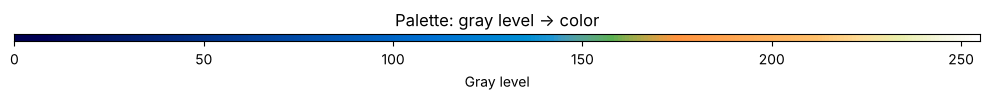

In [4]:
# (gri seviye, (a*, b*)) çapa noktaları:
# lacivert → mavi → açık mavi → (dar yeşil geçiş) → turuncu → soluk sarı-yeşil (çok ince madde) → beyaz
ANCHORS = [(0, (25, -55)), (110, (5, -60)), (142, (-10, -40)), (158, (-45, 40)),
           (175, (35, 60)), (212, (25, 55)), (224, (2, 38)), (234, (-12, 32)), (246, (-4, 10)), (255, (0, 0))]

def build_palette(anchors):
    levels = np.arange(256, dtype=np.uint8)
    as_bgr = cv2.cvtColor(levels.reshape(1, -1), cv2.COLOR_GRAY2BGR).astype(np.float32) / 255
    L = cv2.cvtColor(as_bgr, cv2.COLOR_BGR2Lab)[0, :, 0]              # gri seviyenin kendi açıklığı
    xs = [g for g, _ in anchors]
    a = np.interp(levels, xs, [ab[0] for _, ab in anchors])
    b = np.interp(levels, xs, [ab[1] for _, ab in anchors])
    lab = np.dstack([L, a, b]).astype(np.float32)
    bgr_float = cv2.cvtColor(lab, cv2.COLOR_Lab2BGR)[0]
    return np.clip(np.rint(bgr_float * 255), 0, 255).astype(np.uint8)  # 256 × 3, BGR

PALETTE = build_palette(ANCHORS)

def colorize(gray, palette=PALETTE):
    return palette[gray]          # her piksel, kendi gri seviyesinin rengini alır

colored = [colorize(g) for g in grays]
for g, c in zip(grays, colored):
    assert np.array_equal(c, cv2.applyColorMap(g, PALETTE.reshape(256, 1, 3)))

luma_back = bgr_to_gray(PALETTE.reshape(1, 256, 3))[0].astype(int)
print('Renklendirme cv2.applyColorMap ile birebir aynı.')
print(f'Paletin griye geri çevrilmiş hali ile gri seviye arasındaki fark: ortalama '
      f'{np.abs(luma_back - np.arange(256)).mean():.1f}, en çok {np.abs(luma_back - np.arange(256)).max()} seviye '
      '(fark, ekranda gösterilemeyen doygun renklerin kırpılmasından gelir)')

fig, ax = plt.subplots(figsize=(10, 1.1))
ax.imshow(cv2.cvtColor(PALETTE.reshape(1, 256, 3), cv2.COLOR_BGR2RGB), aspect='auto', extent=(0, 255, 0, 1))
ax.set_yticks([]); ax.set_xlabel('Gray level'); ax.set_title('Palette: gray level → color')
fig.tight_layout(); fig.savefig(OUT / 'task5_palette.png', dpi=110); plt.show()

## 4. Sonuçlar ve orijinalle karşılaştırma

Her satırda: orijinal sahte renkli görüntü, gri görüntü, bizim renklendirmemiz ve iki renkli görüntü arasındaki algısal renk farkı (CIELAB ΔE). ΔE haritasında koyu bölgeler orijinale yakın, parlak bölgeler farklı renklendirilmiş yerlerdir.

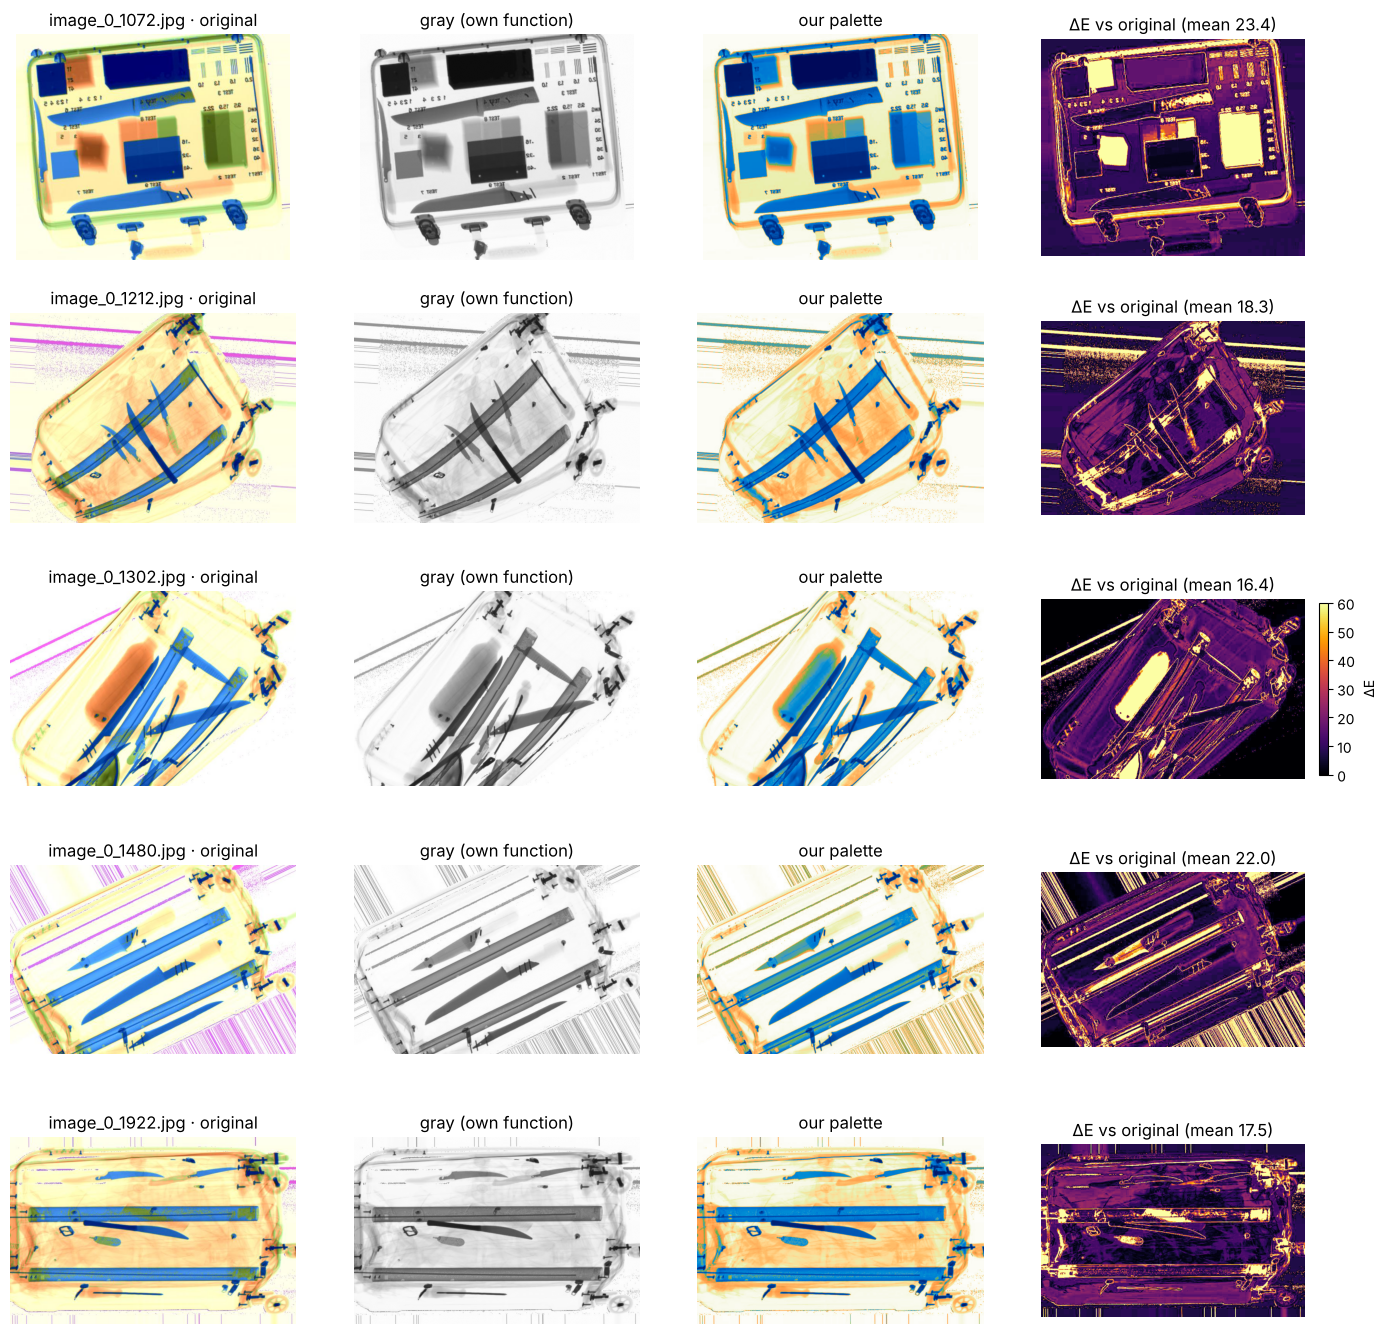

In [5]:
def delta_e(a_bgr, b_bgr):
    to_lab = lambda im: cv2.cvtColor(im.astype(np.float32) / 255, cv2.COLOR_BGR2Lab)
    return np.linalg.norm(to_lab(a_bgr) - to_lab(b_bgr), axis=2)

rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(len(SELECTED), 4, figsize=(17, 3.4 * len(SELECTED)))
for row, name, im, g, c in zip(axes, SELECTED, originals, grays, colored):
    de = delta_e(im, c)
    row[0].imshow(rgb(im)); row[0].set_title(f'{name} · original')
    row[1].imshow(g, cmap='gray', vmin=0, vmax=255); row[1].set_title('gray (own function)')
    row[2].imshow(rgb(c)); row[2].set_title('our palette')
    shown = row[3].imshow(de, cmap='inferno', vmin=0, vmax=60); row[3].set_title(f'ΔE vs original (mean {de.mean():.1f})')
    for ax in row:
        ax.axis('off')
fig.colorbar(shown, ax=axes[:, 3], fraction=0.03, label='ΔE')
fig.savefig(OUT / 'task5_xray.png', dpi=80, bbox_inches='tight')
plt.show()

In [6]:
# Sayısal karşılaştırma: renk farkı ve orijinaldeki renk sınıfının ne kadarının korunduğu.
confusion = np.zeros((4, 4), np.int64)   # satır: orijinal sınıf, sütun: bizim sınıf (none, blue, green, orange)
print(f'{"Görüntü":<18} {"ort. ΔE":>8} {"MAE (B, G, R)":>20}')
for name, im, c in zip(SELECTED, originals, colored):
    mae = np.abs(im.astype(int) - c.astype(int)).mean(axis=(0, 1))
    print(f'{name:<18} {delta_e(im, c).mean():8.1f} {str(mae.round(1)):>20}')
    np.add.at(confusion, (tone_class(im).ravel(), tone_class(c).ravel()), 1)

print('\nOrijinalde bu renkte olan doygun piksellerin bizim görüntüde aynı renkte olma oranı:')
for k, name in enumerate(TONES, start=1):
    print(f'  {name:<7}: {confusion[k, k] / confusion[k].sum():5.1%}   '
          f'(bizde → mavi {confusion[k, 1] / confusion[k].sum():.0%}, yeşil {confusion[k, 2] / confusion[k].sum():.0%}, '
          f'turuncu {confusion[k, 3] / confusion[k].sum():.0%})')

Görüntü             ort. ΔE        MAE (B, G, R)
image_0_1072.jpg       23.4     [33.3  8.6 27.8]
image_0_1212.jpg       18.3     [27.2  7.3 17.9]
image_0_1302.jpg       16.4     [24.5  6.3 17.8]


image_0_1480.jpg       22.0     [34.6  7.1 15.8]
image_0_1922.jpg       17.5     [26.6  7.1 20.4]

Orijinalde bu renkte olan doygun piksellerin bizim görüntüde aynı renkte olma oranı:
  blue   : 93.5%   (bizde → mavi 93%, yeşil 5%, turuncu 1%)
  green  :  6.8%   (bizde → mavi 53%, yeşil 7%, turuncu 27%)
  orange : 80.6%   (bizde → mavi 10%, yeşil 5%, turuncu 81%)


### Neden gökkuşağı (JET) paleti değil?

Karşılaştırma için aynı gri görüntü OpenCV'nin `COLORMAP_JET` paletiyle de renklendirildi. JET'te açıklık tekdüze değildir: arka plan koyu kırmızıya döner, orta seviyelerdeki küçük farklar sarı–camgöbeği sınırında sert kenarlar gibi görünür ve renklerin operatörün bildiği madde anlamıyla hiçbir ilgisi yoktur.

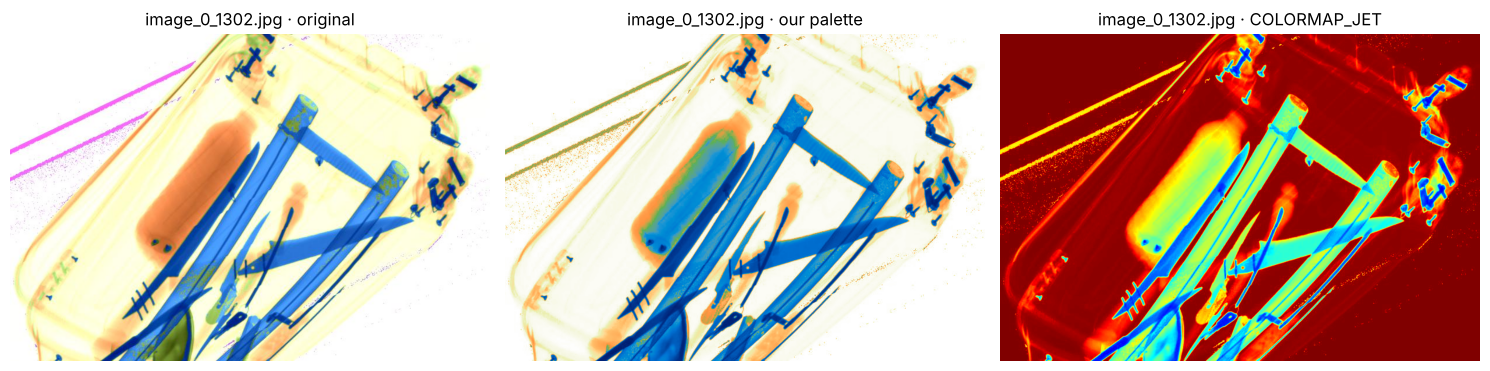

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
k = 2
for ax, (im, title) in zip(axes, [(originals[k], 'original'), (colored[k], 'our palette'),
                                  (cv2.applyColorMap(grays[k], cv2.COLORMAP_JET), 'COLORMAP_JET')]):
    ax.imshow(rgb(im)); ax.set_title(f'{SELECTED[k]} · {title}'); ax.axis('off')
fig.tight_layout(); plt.show()

## 5. Farkların yorumu

Renklendirdiğimiz görüntü orijinale genel olarak benziyor: metal bıçaklar ve çubuklar mavi, ince organik bölgeler turuncu, arka plan açık. Ama iki görüntü aynı değil ve farkın nedeni paletten çok **bilginin kendisinde**:

- **Orijinal renk iki ölçümden geliyor, gri görüntü tek ölçüm.** Tarayıcı aynı çantayı yüksek ve düşük enerjiyle iki kez görüntüler (veri setindeki `HighLow` klasörü). İki enerjideki zayıflama oranı maddenin **etkin atom numarasını** (Zeff) verir ve renk buna göre seçilir; bu oran kalınlıktan büyük ölçüde bağımsızdır. Gri görüntüde ise yalnızca toplam zayıflama vardır: kalınlık ve madde karışmıştır. İnce bir metal ile kalın bir organik nesne aynı gri seviyede olabilir.
- **Kalın organik nesneler mavi ya da yeşil görünüyor.** `image_0_1072`'deki kahverengi/turuncu test blokları koyu olduğu için bizde mavi; `image_0_1302`'deki turuncu şişe ise tam belirsiz bölgeye düştüğü için yeşil-mavi görünüyor. Gerçek kullanımda bu, organik bir maddenin metal sanılmasına, yani yanlış yorumlamaya yol açabilir. ΔE haritalarındaki en parlak bölgeler bunlar.
- **Yeşil (karışık madde) neredeyse hiç geri gelmiyor.** Orijinalde yeşil olan piksellerin yalnızca küçük bir kısmı bizde yeşil; yarısı maviye, kalanın çoğu turuncuya gidiyor. Orijinaldeki koyu yeşil test blokları bizde mavi. Yeşilin gri seviyesi mavi ve turuncuyla çakıştığı için yalnızca gri bilgiden "karışık madde" ayrımı yapılamaz.
- **İnce metal kenarları ve tarama çizgileri.** Açık gri kalan ince metal parçalar ve bıçak kenarları (ör. `image_0_1480`'deki üstteki ince bıçak) yeşil/turuncu banda düşebiliyor. Orijinaldeki mor tarama artefaktları (dedektör çizgileri) bizde ton bilgisi kaybolduğu için yeşilimsi çizgilere dönüşüyor.
- **Arka plan.** Orijinalin krem rengi arka planı bizde neredeyse beyaz; bu bilinçli bir seçim (nesneler daha iyi öne çıkıyor) ve ΔE'ye küçük ama yaygın bir katkı yapıyor.

**Sonuç:** Paletimiz gri görüntüyü operatörün alışık olduğu renk diliyle, ayrıntı kaybı olmadan ve gri görüntüden çok daha kolay okunur hale getiriyor; yoğun nesneler (bıçaklar) hemen göze çarpıyor. Ancak bu bir **yoğunluk renklendirmesidir, madde renklendirmesi değildir**. Organik/inorganik ayrımı yalnızca çift enerjili ölçümle yapılabilir; güvenlik kararı için orijinal sahte renkli görüntünün yerini tutamaz.